# 06 Evaluate and export

**Purpose.** Retrain the chosen models on every training day, check them once on the held-out week against their baselines, and export them for `silip_ml` with a parity sample that guards against train/serve drift.

**Data.** `data/sim/` (dev scale, seed 7). The last 7 days are the held-out week, the same split `make backtest` uses.

**Outcome.** `models/forecaster/lightgbm/` and `models/risk_scorer/lightgbm/`: LightGBM text model, `metadata.json`, and `parity/` CSVs that `tests/ml/test_parity.py` must reproduce.

In [1]:
import hashlib
import json
import platform
from datetime import date

import lightgbm as lgb
import numpy as np
import pandas as pd
import sklearn
from _data import DATA_DIR, HOLIDAYS, MODELS_DIR, holdout_start, load_tables
from _features import LOAD_FEATURES, RISK_FEATURES, load_features, risk_features, to_grid, trip_labels
from _models import SEED, day_ahead, fit_load_model, load_table, read_result, recall_and_false_alarms, risk_examples, rolling_day_ahead
from _style import COLORS, label
import plotly.express as px

tables = load_tables()
load, transformers = tables["load"], tables["transformers"]
cutoff = holdout_start(load)
holdout_days = pd.date_range(cutoff, periods=7, freq="D")
load_choice, risk_choice = read_result("04_load_forecast"), read_result("05_risk")
print(f"held-out week: {holdout_days[0]:%Y-%m-%d} to {holdout_days[-1]:%Y-%m-%d}")

held-out week: 2026-05-20 to 2026-05-26


## Retrain the load forecast on every training day
Every feature is at least one day old, so the features of a held-out day are exactly what a 00:00 forecast for that day would see.

In [2]:
table = load_table(load, HOLIDAYS)
table = table[table["ts"] >= table["ts"].min() + pd.Timedelta(days=7)]
train_table = table[table["ts"] < cutoff]
load_model = fit_load_model(train_table, load_choice["params"])
holdout_forecast = day_ahead(load_model, table[table["ts"] >= cutoff])
print(f"trained on {len(train_table.dropna(subset=['transformer_kw'])):,} intervals up to {train_table['ts'].max()}")

trained on 199,832 intervals up to 2026-05-19 23:45:00+08:00


## Seasonal naive, exactly as `silip_ml` computes it
Same slot last week; a missing slot falls back to that transformer's mean over the week before the forecast day.

In [3]:
grid = to_grid(load)
naive = []
for day in holdout_days:
    last_week = grid.loc[day - pd.Timedelta(days=7) : day - pd.Timedelta(minutes=15)]
    guess = last_week.iloc[:96].reset_index(drop=True).fillna(last_week.mean())
    guess.index = pd.date_range(day, periods=96, freq="15min")
    naive.append(guess.stack(future_stack=True).rename("kw_pred").rename_axis(["ts", "transformer_id"]).reset_index())
naive = pd.concat(naive, ignore_index=True)

actual = load[load["ts"] >= cutoff][["transformer_id", "ts", "transformer_kw"]]


def load_mae(forecast: pd.DataFrame) -> tuple[float, int]:
    joined = forecast.merge(actual, on=["transformer_id", "ts"])
    return float((joined["kw_pred"] - joined["transformer_kw"]).abs().mean()), len(joined)


mae_naive, n_intervals = load_mae(naive)
mae_lgbm, _ = load_mae(holdout_forecast)
print(f"held-out load MAE: seasonal naive {mae_naive:.3f} kW, LightGBM {mae_lgbm:.3f} kW over {n_intervals:,} intervals")

held-out load MAE: seasonal naive 7.821 kW, LightGBM 4.753 kW over 32,830 intervals


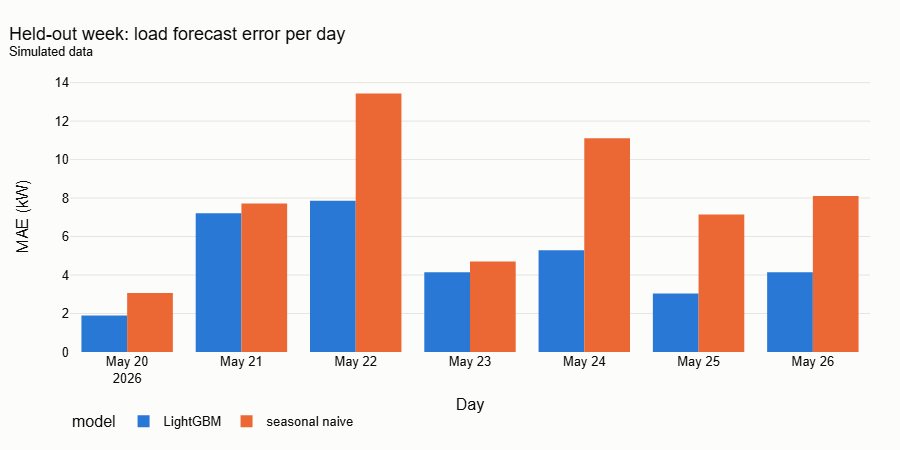

In [4]:
daily = pd.concat([
    holdout_forecast.merge(actual).assign(model="LightGBM"),
    naive.merge(actual).assign(model="seasonal naive"),
])
daily["abs_error"] = (daily["kw_pred"] - daily["transformer_kw"]).abs()
daily = daily.groupby([daily["ts"].dt.normalize().rename("day"), "model"])["abs_error"].mean().reset_index()
fig = px.bar(daily, x="day", y="abs_error", color="model", barmode="group", color_discrete_sequence=COLORS)
label(fig, "Held-out week: load forecast error per day", "Day", "MAE (kW)").show()

Takeaway: LightGBM wins on every held-out day. Its worst day is the typhoon (May 22): no lag can see a storm coming.

## Retrain the risk model on every training day
As in `05`: features come from out-of-sample day-ahead forecasts (weekly refits), labels from the trip rule on true load.

In [5]:
first_day = pd.Timestamp(risk_choice["first_training_day"])
labels = trip_labels(load, transformers)
train_forecasts = rolling_day_ahead(table, load_choice["params"], first_day, cutoff)
train_examples = risk_examples(train_forecasts, transformers, labels)
risk_model = lgb.LGBMClassifier(**risk_choice["params"], random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)
risk_model.fit(train_examples[RISK_FEATURES].to_numpy(dtype=np.float64), train_examples["tripped"].astype(int))
thresholds = risk_choice["thresholds"]
print(f"{len(train_examples):,} training transformer-days, {int(train_examples['tripped'].sum())} trips; thresholds {thresholds}")

1,750 training transformer-days, 207 trips; thresholds {'critical': 0.08, 'watch': 0.04}


In [6]:
holdout_examples = risk_examples(holdout_forecast, transformers, labels)
score = risk_model.booster_.predict(holdout_examples[RISK_FEATURES].to_numpy(dtype=np.float64))
flag_model = pd.Series(score >= thresholds["critical"], index=holdout_examples.index)
flag_rules = holdout_examples["hours_over_100"] * 4 >= 8
risk_model_metrics = recall_and_false_alarms(flag_model, holdout_examples["tripped"])
risk_rules_metrics = recall_and_false_alarms(flag_rules, holdout_examples["tripped"])
lead_h = (holdout_examples["trip_ts"] - holdout_examples["day"]).dt.total_seconds() / 3600
early = holdout_examples["tripped"] & (lead_h >= 12)

## Held-out results (Simulated)
The run-backtest report format. Risk rows use the LightGBM load forecast for both scorers, so the comparison isolates the scorer. Outage rows are unchanged by this notebook; `make backtest` reports them.

In [7]:
report = pd.DataFrame([
    ["Risk recall, next 24 h scored at 00:00", risk_rules_metrics["recall"], risk_model_metrics["recall"], f"{risk_rules_metrics['trips']} trips"],
    ["Risk recall at >= 12 h lead", (flag_rules & early).sum() / early.sum(), (flag_model & early).sum() / early.sum(), f"{int(early.sum())} trips"],
    ["False alarms per transformer-month", risk_rules_metrics["false_alarms_per_tx_month"], risk_model_metrics["false_alarms_per_tx_month"], f"{risk_rules_metrics['windows']} transformer-days"],
    ["Load MAE (kW)", mae_naive, mae_lgbm, f"{n_intervals:,} intervals"],
], columns=["Metric (Simulated)", "Baseline", "Strategy", "n"])
report.insert(1, "Baseline name", ["rules", "rules", "rules", "seasonal_naive"])
report.insert(3, "Strategy name", ["lightgbm"] * 4)
report.round(3)

,Metric (Simulated),Baseline name,Baseline,Strategy name,Strategy,n
0,"Risk recall, next 24 h scored at 00:00",rules,0.960,lightgbm,1.000,25 trips
1,Risk recall at >= 12 h lead,rules,0.960,lightgbm,1.000,25 trips
2,False alarms per transformer-month,rules,8.657,lightgbm,9.257,350 transformer-days
3,Load MAE (kW),seasonal_naive,7.821,lightgbm,4.753,"32,830 intervals"


## Keep only what beats its baseline
Load: lower MAE. Risk: higher recall *and* no more false alarms than the rules (the budget set in `05`). A model that fails is still exported, so the strategy stays runnable and guarded by the parity test, but its metadata says `kept: false` and the configured default stays the baseline.

In [8]:
keep_load = mae_lgbm < mae_naive
keep_risk = (risk_model_metrics["recall"] > risk_rules_metrics["recall"]) and (
    risk_model_metrics["false_alarms_per_tx_month"] <= risk_rules_metrics["false_alarms_per_tx_month"]
)
print(f"keep load forecast: {keep_load}; keep risk model: {keep_risk}")
assert keep_load, "the load forecast lost to seasonal naive on the held-out week; do not ship it"

keep load forecast: True; keep risk model: False


Takeaway: the load forecast clearly wins. The risk model catches every held-out trip (one more than the rules) but raises a few more false alarms, so it does not strictly beat the rules: it is exported as a candidate (`kept: false`) and `RISK_SCORER=rules` stays the default. The threshold was not re-tuned on the held-out week; doing so would make this check meaningless.

## Export
LightGBM native text (never pickle) plus `metadata.json`: features, parameters, training window, data seed and fingerprint, metrics, library versions. `silip_ml` reads the feature list and parameters from here, never from a hardcoded copy.

In [9]:
data_sha256 = hashlib.sha256((DATA_DIR / "transformer_load_15m.csv").read_bytes()).hexdigest()
common = {
    "created": str(date.today()),
    "is_simulated": True,
    "data": {"dir": "data/sim", "scale": "dev", "seed": 7, "transformer_load_sha256": data_sha256, "transformers": len(transformers)},
    "holdout_start": str(cutoff),
    "versions": {"python": platform.python_version(), "lightgbm": lgb.__version__, "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "trained_in": "notebooks/06_evaluate_and_export.ipynb",
}


def export(task: str, name: str, booster: lgb.Booster, metadata: dict, parity: dict[str, pd.DataFrame]) -> None:
    folder = MODELS_DIR / task / name
    (folder / "parity").mkdir(parents=True, exist_ok=True)
    booster.save_model(str(folder / "model.txt"))
    (folder / "metadata.json").write_text(json.dumps({"task": task, "name": name, **metadata, **common}, indent=2) + "\n", encoding="utf-8")
    for file, frame in parity.items():
        frame.assign(is_simulated=True).to_csv(folder / "parity" / file, index=False)

### Parity sample for the load forecast
Three transformers' last eight training days (one with a gap), the features the notebook builds for the next 24 h, and the predictions. `silip_ml` must reproduce both from the input rows alone.

In [10]:
recent = load[(load["ts"] >= cutoff - pd.Timedelta(days=8)) & (load["ts"] < cutoff)]
counts = recent.groupby("transformer_id").size()
last_ok = set(recent.loc[recent["ts"] == recent["ts"].max(), "transformer_id"])
with_gap = [t for t in counts[counts < counts.max()].index if t in last_ok][:1]
complete = [t for t in counts[counts == counts.max()].index if t in last_ok][:3 - len(with_gap)]
parity_ids = sorted(with_gap + complete)
parity_input = recent[recent["transformer_id"].isin(parity_ids)][["transformer_id", "ts", "transformer_kw"]]
last_ts = parity_input["ts"].max()
parity_grid = to_grid(parity_input, until=last_ts + pd.Timedelta(minutes=15 * 96))
parity_features = load_features(parity_grid, HOLIDAYS)
parity_features = parity_features[parity_features["ts"] > last_ts][["transformer_id", "ts"] + LOAD_FEATURES]
parity_pred = parity_features[["transformer_id", "ts"]].assign(kw_pred=load_model.booster_.predict(parity_features[LOAD_FEATURES].to_numpy(dtype=np.float64)))
print(f"parity transformers {parity_ids} (with a gap: {with_gap}); {len(parity_input)} input rows, {len(parity_pred)} predictions")

export(
    "forecaster", "lightgbm", load_model.booster_,
    {
        "features": LOAD_FEATURES,
        "feature_params": {"holidays": HOLIDAYS, "step_minutes": 15, "steps_per_day": 96},
        "target": "transformer_kw",
        "max_horizon_steps": 96,
        "params": load_choice["params"],
        "training_window": {"start": str(train_table["ts"].min()), "end": str(train_table["ts"].max())},
        "kept": bool(keep_load),
        "metrics": {"holdout_mae_kw": mae_lgbm, "baseline_seasonal_naive_mae_kw": mae_naive, "intervals": n_intervals},
    },
    {"input_load.csv": parity_input, "features.csv": parity_features, "predictions.csv": parity_pred},
)

parity transformers ['T-100', 'T-101', 'T-102'] (with a gap: ['T-100']); 2285 input rows, 288 predictions


### Parity sample for the risk model
Ten transformers' first held-out-day forecast (including every one that tripped), their features, scores and tiers.

In [11]:
first_day_forecast = holdout_forecast[holdout_forecast["ts"].dt.normalize() == holdout_days[0]]
day_examples = holdout_examples[holdout_examples["day"] == holdout_days[0]]
risk_ids = sorted(set(day_examples.loc[day_examples["tripped"], "transformer_id"]) | set(day_examples.sort_values("peak_load_pct")["transformer_id"].iloc[::5]))[:10]
risk_input = first_day_forecast[first_day_forecast["transformer_id"].isin(risk_ids)]
risk_transformers = transformers[transformers["transformer_id"].isin(risk_ids)][["transformer_id", "rated_kva", "coverage_pct"]]
risk_parity_features = risk_features(risk_input, risk_transformers)
risk_score = risk_model.booster_.predict(risk_parity_features[RISK_FEATURES].to_numpy(dtype=np.float64))
risk_tier = np.where(risk_score >= thresholds["critical"], "Critical", np.where(risk_score >= thresholds["watch"], "Watch", "OK"))
risk_pred = risk_parity_features[["transformer_id"]].assign(score=risk_score, tier=risk_tier)

export(
    "risk_scorer", "lightgbm", risk_model.booster_,
    {
        "features": RISK_FEATURES,
        "forecaster": "lightgbm",
        "thresholds": thresholds,
        "kept": bool(keep_risk),
        "kept_reason": "beats rules on recall and false alarms" if keep_risk else "higher recall but more false alarms than rules on the held-out week",
        "false_alarm_budget_per_tx_month": risk_choice["false_alarm_budget_per_tx_month"],
        "label": "trip rule on true load: above 110% of usable rating for 3 h in a row (silip-domain)",
        "params": risk_choice["params"],
        "training_window": {"start": str(first_day), "end": str(cutoff - pd.Timedelta(minutes=15))},
        "metrics": {"holdout_recall": risk_model_metrics["recall"], "holdout_false_alarms_per_tx_month": risk_model_metrics["false_alarms_per_tx_month"],
                    "baseline_rules_recall": risk_rules_metrics["recall"], "baseline_rules_false_alarms_per_tx_month": risk_rules_metrics["false_alarms_per_tx_month"], "trips": risk_rules_metrics["trips"]},
    },
    {"input_forecast.csv": risk_input, "transformers.csv": risk_transformers, "features.csv": risk_parity_features[["transformer_id"] + RISK_FEATURES], "predictions.csv": risk_pred},
)
risk_pred

,transformer_id,score,tier
0,T-107,0.090622,Critical
1,T-109,0.970183,Critical
2,T-113,0.829904,Critical
3,T-118,0.905842,Critical
4,T-119,0.813145,Critical
5,T-124,0.240682,Critical
6,T-126,0.959208,Critical
7,T-128,0.948284,Critical
8,T-129,0.001182,OK
9,T-131,0.004687,OK


## What was written, and how big

In [12]:
sizes = pd.DataFrame([{"file": str(p.relative_to(MODELS_DIR.parent)).replace("\\", "/"), "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(MODELS_DIR.rglob("*")) if p.is_file()])
print(f"total {sizes['KB'].sum():.0f} KB")
sizes

total 784 KB


,file,KB
0,models/forecaster/lightgbm/metadata.json,1.5
1,models/forecaster/lightgbm/model.txt,413.4
2,models/forecaster/lightgbm/parity/features.csv,21.2
3,models/forecaster/lightgbm/parity/input_load.csv,99.9
4,models/forecaster/lightgbm/parity/predictions.csv,15.9
5,models/risk_scorer/lightgbm/metadata.json,1.5
6,models/risk_scorer/lightgbm/model.txt,176.3
7,models/risk_scorer/lightgbm/parity/features.csv,1.0
8,models/risk_scorer/lightgbm/parity/input_forec...,52.9
9,models/risk_scorer/lightgbm/parity/predictions...,0.4


**Outcome.** The load forecast beats seasonal naive and is kept; the risk model is exported as a candidate that does not strictly beat the rules yet. `make backtest` loads these files through `silip_ml` and should print the same held-out numbers; `tests/ml/test_parity.py` checks `silip_ml` rebuilds the same features and predictions.